# Distribution Transformations

This notebook applies **distribution transformations** to two key numerical features: `price` and `areaSqm`. It is the fourth step in the data preparation pipeline, following EDA, missing-value treatment, and outlier removal.

**Why transform distributions:** Many machine learning algorithms (especially linear models like Linear Regression, Ridge, and Lasso) perform best when the target variable and predictors are approximately **normally distributed**. A right-skewed distribution (a long tail to the right) means that a few very large values exert disproportionate influence on the model. By applying a **log transformation**, we compress the long tail, bring the distribution closer to normality, and often improve both the model's accuracy and the validity of statistical assumptions.

We use two diagnostic tools throughout: **histograms with KDE curves** (to visually assess the shape of the distribution) and **Q-Q plots** (to compare the data quantiles against a theoretical normal distribution).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.gofplots import qqplot


In [2]:
df = pd.read_csv("spitogatos_no_outliers.csv")
df.head()


,listingId,airConditioning,alarm,areaSqm,balcony,bathrooms,closedParkingSpots,elevator,energyClass,fireplace,...,pool,price,pricePerSqm,propertyType,renovationYear,rooms,solarHeater,storage,view,yearBuilt
0,20304396,True,False,47.0,False,1.0,0.0,True,C,False,...,False,600,12.77,apartment,2026.0,1.0,False,False,True,1975.0
1,19956518,True,False,25.0,False,1.0,0.0,True,B,False,...,False,530,21.20,apartment,2023.0,1.0,False,False,True,1982.0
2,18383741,False,False,60.0,False,1.0,0.0,True,D,False,...,False,510,8.50,apartment,NaN,1.0,False,False,True,1978.0
3,20242029,True,False,60.0,False,1.0,0.0,True,F,False,...,False,330,5.50,apartment,NaN,1.0,False,False,True,1978.0
4,20055845,True,False,75.0,False,1.0,0.0,True,C,False,...,False,620,8.27,apartment,NaN,2.0,False,False,True,1981.0


## Assessing the Current Distributions

Before applying any transformation, we need a **baseline**. We print the **skewness coefficient** and plot a histogram with a KDE (Kernel Density Estimate) overlay for both `price` and `areaSqm`.

- A skewness of **0** indicates a perfectly symmetric distribution.
- A value **> 0** (positive skew) means the right tail is longer.
- As a rule of thumb, a skewness above **0.5** is considered moderately skewed, and above **1.0** is highly skewed.

The histograms give us an intuitive visual confirmation, while the numeric skewness values let us track the improvement after transformation.


2.5083033619191664
1.2857644369145496


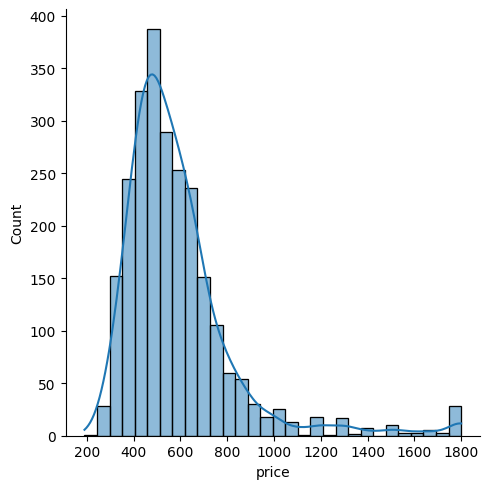

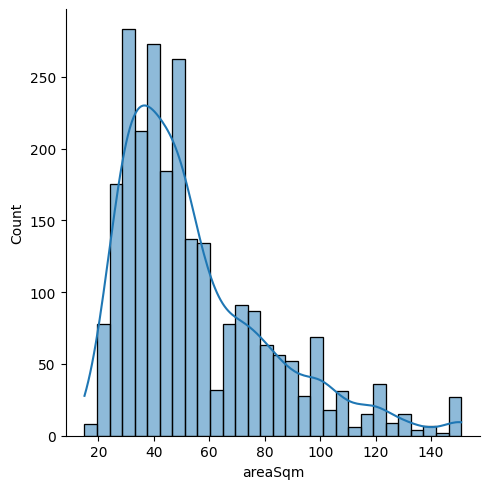

In [3]:
for i in ["price", "areaSqm"]:
    print(df[i].skew())
    sns.displot(df[i], kde=True, bins=30)


## Transforming `price`

### Q-Q Plot of the Original `price`

A **Q-Q (Quantile-Quantile) plot** compares the distribution of our data against a theoretical normal distribution. If the data points fall on the red reference line, the feature is normally distributed. Deviations from the line, especially at the tails, indicate departures from normality. We expect the right tail to curve upward, confirming the positive skew we saw in the histogram.


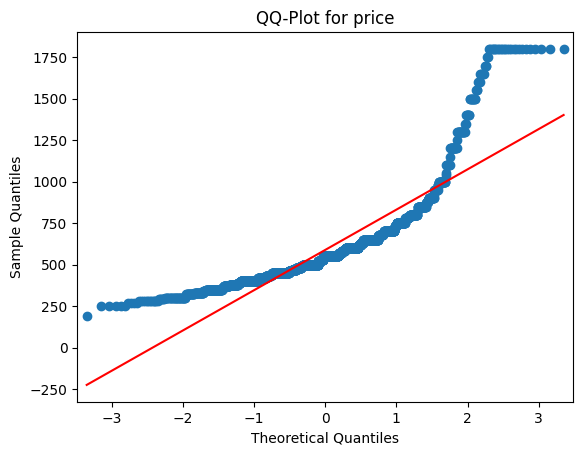

In [4]:
data = df["price"]
qqplot(data, line="s")
plt.title(f"QQ-Plot for price")
plt.show()


### Q-Q Plot After Log Transformation

We now apply a **logarithm** transformation (`np.log`) to `price` and plot the Q-Q plot again. The log function compresses large values more than small values, which has the effect of pulling in the right tail. If the transformation is successful, the points should align much more closely with the reference line.


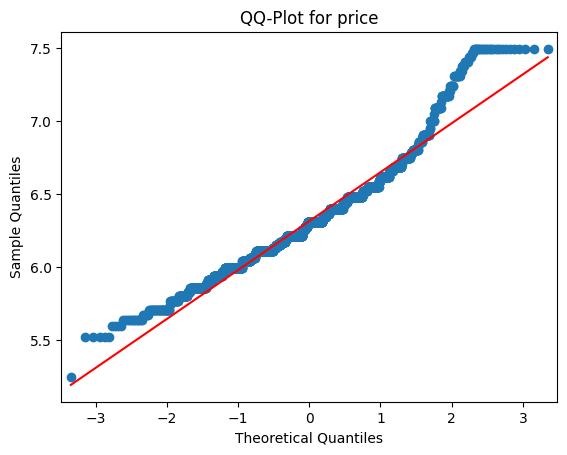

In [5]:
data = np.log(df["price"])
qqplot(data, line="s")
plt.title(f"QQ-Plot for price")
plt.show()


### Applying the Log Transformation to `price`

Satisfied that the log transformation improves normality, we permanently overwrite the `price` column with its log-transformed values. From this point onward, the model will work with `log(price)` as the target variable.

In [6]:
df["price"] = np.log(df["price"])


### Verifying the Transformed Distribution

We print the new skewness value and plot the histogram again. We expect the skewness to be much closer to 0 and the KDE curve to resemble a bell shape, confirming that the log transformation successfully normalised the distribution.


0.8793771002170955


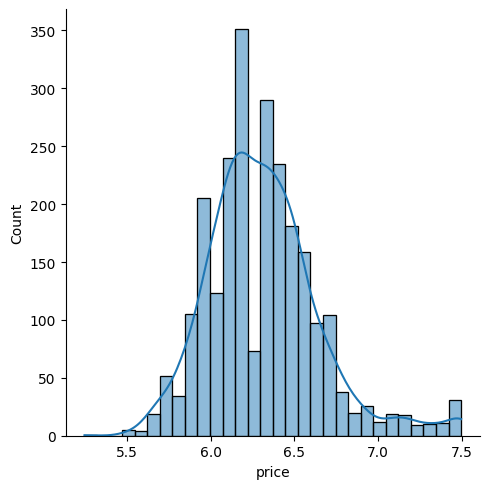

In [7]:
print(df["price"].skew())
sns.displot(df["price"], kde=True, bins=30)


## Transforming `areaSqm`

We repeat the same workflow for `areaSqm`, which was identified during EDA as the strongest predictor of rent price.

### Q-Q Plot of the Original `areaSqm`


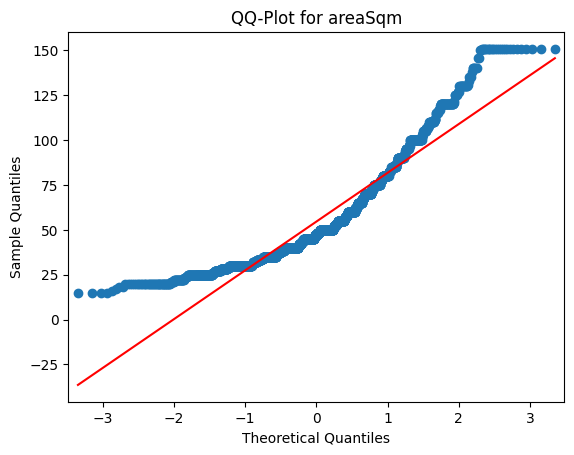

In [8]:
data = df["areaSqm"]
qqplot(data, line="s")
plt.title(f"QQ-Plot for areaSqm")
plt.show()


### Q-Q Plot After Log Transformation

We apply the log transformation and re-examine the Q-Q plot. As with `price`, we expect the points to align more closely with the reference line, indicating a distribution that is closer to normal.


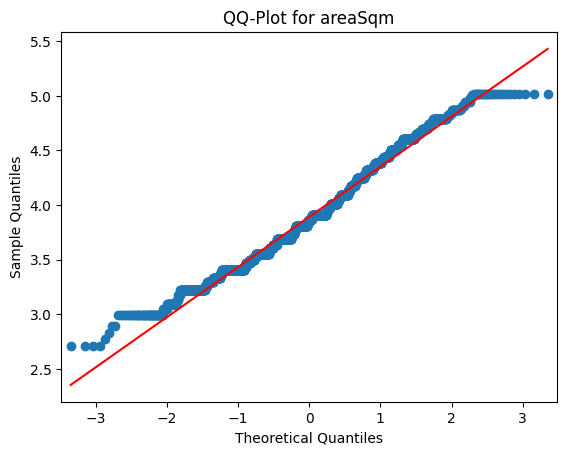

In [9]:
data = np.log(df["areaSqm"])
qqplot(data, line="s")
plt.title(f"QQ-Plot for areaSqm")
plt.show()


In [10]:
df["areaSqm"] = np.log(df["areaSqm"])


### Verifying the Transformed Distribution

We print the new skewness value and re-plot the histogram to confirm the improvement. A skewness near 0 and a roughly symmetric histogram indicate that the log transformation was effective.


0.29484654746399425


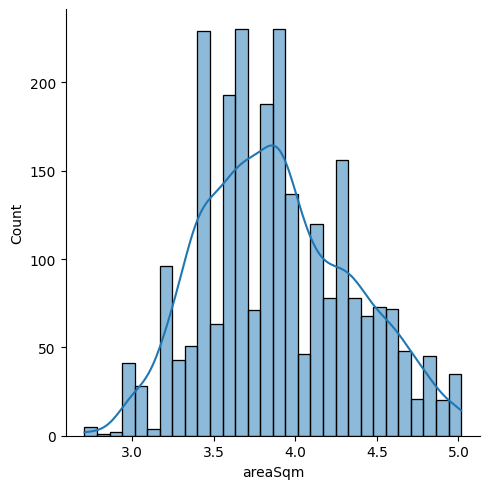

In [11]:
print(df["areaSqm"].skew())
sns.displot(df["areaSqm"], kde=True, bins=30)


In [12]:
df.head()


,listingId,airConditioning,alarm,areaSqm,balcony,bathrooms,closedParkingSpots,elevator,energyClass,fireplace,...,pool,price,pricePerSqm,propertyType,renovationYear,rooms,solarHeater,storage,view,yearBuilt
0,20304396,True,False,3.850148,False,1.0,0.0,True,C,False,...,False,6.396930,12.77,apartment,2026.0,1.0,False,False,True,1975.0
1,19956518,True,False,3.218876,False,1.0,0.0,True,B,False,...,False,6.272877,21.20,apartment,2023.0,1.0,False,False,True,1982.0
2,18383741,False,False,4.094345,False,1.0,0.0,True,D,False,...,False,6.234411,8.50,apartment,NaN,1.0,False,False,True,1978.0
3,20242029,True,False,4.094345,False,1.0,0.0,True,F,False,...,False,5.799093,5.50,apartment,NaN,1.0,False,False,True,1978.0
4,20055845,True,False,4.317488,False,1.0,0.0,True,C,False,...,False,6.429719,8.27,apartment,NaN,2.0,False,False,True,1981.0


In [13]:
df.to_csv('spitogatos_transforms.csv', index=False)
